# TF-IDF Demonstration
This notebook demonstrates how Term Frequency-Inverse Document Frequency (TF-IDF) works using `scikit-learn` to extract and weight terms from a text corpus.

In [1]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [8]:
corpus = [
    "Thor eating pizza, Loki is eating pizza, Ironman ate pizza already",
    "Apple is announcing new iphone tomorrow",
    "Tesla is announcing new model-3 tomorrow",
    "Google is announcing new pixel-6 tomorrow",
    "Microsoft is announcing new surface tomorrow",
    "Amazon is announcing new eco-dot tomorrow",
    "I am eating biryani and you are eating grapes"
]

In [9]:
v = TfidfVectorizer()
v.fit(corpus)
transformed_output = v.transform(corpus)

In [11]:
print(v.vocabulary_)

{'thor': 25, 'eating': 10, 'pizza': 22, 'loki': 17, 'is': 16, 'ironman': 15, 'ate': 7, 'already': 0, 'apple': 5, 'announcing': 4, 'new': 20, 'iphone': 14, 'tomorrow': 26, 'tesla': 24, 'model': 19, 'google': 12, 'pixel': 21, 'microsoft': 18, 'surface': 23, 'amazon': 2, 'eco': 11, 'dot': 9, 'am': 1, 'biryani': 8, 'and': 3, 'you': 27, 'are': 6, 'grapes': 13}


In [13]:
v.get_feature_names_out()

array(['already', 'am', 'amazon', 'and', 'announcing', 'apple', 'are',
       'ate', 'biryani', 'dot', 'eating', 'eco', 'google', 'grapes',
       'iphone', 'ironman', 'is', 'loki', 'microsoft', 'model', 'new',
       'pixel', 'pizza', 'surface', 'tesla', 'thor', 'tomorrow', 'you'],
      dtype=object)

## Inverse Document Frequency (IDF) of Each Word
Below, we calculate and display the IDF score for each word in the vocabulary. Words that are common across all documents (like 'is', 'new', 'tomorrow') will have a lower IDF score, while unique or rare words (like 'amazon', 'pizza', 'tesla') will have a higher IDF score.

let's print the idf of each word:

In [14]:
all_feature_names = v.get_feature_names_out()

for word in all_feature_names:
  # get index in vocab
  index = v.vocabulary_.get(word)
  # get score
  idf_score = v.idf_[index]
  print(f"{word} : {idf_score}")



already : 2.386294361119891
am : 2.386294361119891
amazon : 2.386294361119891
and : 2.386294361119891
announcing : 1.2876820724517808
apple : 2.386294361119891
are : 2.386294361119891
ate : 2.386294361119891
biryani : 2.386294361119891
dot : 2.386294361119891
eating : 1.9808292530117262
eco : 2.386294361119891
google : 2.386294361119891
grapes : 2.386294361119891
iphone : 2.386294361119891
ironman : 2.386294361119891
is : 1.1335313926245225
loki : 2.386294361119891
microsoft : 2.386294361119891
model : 2.386294361119891
new : 1.2876820724517808
pixel : 2.386294361119891
pizza : 2.386294361119891
surface : 2.386294361119891
tesla : 2.386294361119891
thor : 2.386294361119891
tomorrow : 1.2876820724517808
you : 2.386294361119891


## TF-IDF Transformed Output Matrix
Each document in the corpus is represented as a vector. The length of this vector equals the number of unique words in our vocabulary.

For example, in the document `"Apple is announcing new iphone tomorrow"`, common words like `'tomorrow'` and `'new'` receive lower weights, whereas highly specific terms like `'apple'` and `'iphone'` receive much higher TF-IDF weights.

In [15]:
print(transformed_output.toarray())

[[0.24266547 0.         0.         0.         0.         0.
  0.         0.24266547 0.         0.         0.40286636 0.
  0.         0.         0.         0.24266547 0.11527033 0.24266547
  0.         0.         0.         0.         0.72799642 0.
  0.         0.24266547 0.         0.        ]
 [0.         0.         0.         0.         0.30652086 0.5680354
  0.         0.         0.         0.         0.         0.
  0.         0.         0.5680354  0.         0.26982671 0.
  0.         0.         0.30652086 0.         0.         0.
  0.         0.         0.30652086 0.        ]
 [0.         0.         0.         0.         0.30652086 0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.26982671 0.
  0.         0.5680354  0.30652086 0.         0.         0.
  0.5680354  0.         0.30652086 0.        ]
 [0.         0.         0.         0.         0.30652086 0.
  0.         0.         0.         0.         0.         0.
  0.

# Application: Product Classification
Given a description of a product sold on an e-commerce website (`Ecommerce_data.csv`), we want to classify it into one of four distinct categories.

### Dataset Credits
[E-commerce Text Classification Dataset on Kaggle](https://www.kaggle.com/datasets/saurabhshahane/ecommerce-text-classification)

This dataset consists of two columns:
* **Text**: Description of an item sold on the e-commerce website.
* **Label**: Category of that item. There are 4 balanced categories: **Household**, **Electronics**, **Books**, and **Clothing & Accessories** (covering approximately 80% of any e-commerce inventory).

## Setup & Imports
First, let's import the necessary libraries for data processing, pipeline building, classification models, and evaluation.

In [57]:
import pandas as pd
import spacy
from matplotlib import pyplot as plt
import seaborn as sn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

## Read the Dataset into a Pandas DataFrame
We load the CSV file and examine its dimensions along with a quick preview of the first few records.

In [18]:

df = pd.read_csv("Ecommerce_data.csv")
print(df.shape)
df.head(5)

(24000, 2)


,Text,label
0,Urban Ladder Eisner Low Back Study-Office Comp...,Household
1,"Contrast living Wooden Decorative Box,Painted ...",Household
2,IO Crest SY-PCI40010 PCI RAID Host Controller ...,Electronics
3,ISAKAA Baby Socks from Just Born to 8 Years- P...,Clothing & Accessories
4,Indira Designer Women's Art Mysore Silk Saree ...,Clothing & Accessories


In [19]:
df.label.value_counts()

,count
label,
Household,6000
Electronics,6000
Clothing & Accessories,6000
Books,6000


We can see that the dataset contains exactly 6,000 samples for each label. Because the classes are perfectly balanced, we do not need to apply any class-imbalance mitigation techniques such as oversampling (SMOTE) or undersampling.

## Label Encoding
To prepare the labels for machine learning algorithms, we map each text category to a unique numerical index.

In [20]:
df["target"] = df["label"].map(
    {
        "Household": 0,
        "Books": 1,
        "Electronics": 2,
        "Clothing & Accessories": 3
    }
)

In [21]:
df.head()

,Text,label,target
0,Urban Ladder Eisner Low Back Study-Office Comp...,Household,0
1,"Contrast living Wooden Decorative Box,Painted ...",Household,0
2,IO Crest SY-PCI40010 PCI RAID Host Controller ...,Electronics,2
3,ISAKAA Baby Socks from Just Born to 8 Years- P...,Clothing & Accessories,3
4,Indira Designer Women's Art Mysore Silk Saree ...,Clothing & Accessories,3


# 1. Build & evaluation  - No Text preprocessing


We will train our models using raw text representations. Let's compare three different classifiers using a Scikit-Learn Pipeline combining `TfidfVectorizer` and each respective estimator.

## Train-Test Split
We split our data into training (80%) and testing (20%) sets. We use stratified splitting to ensure both sets maintain the exact same proportion of target classes.

In [27]:
X = df.Text
y = df.target

X_test, X_train, y_test, y_train = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=df.target
)

print("X_train #rows:", X_train.shape[0])
print("X_test #rows:", X_test.shape[0])

print("y train classe rate", y_train.value_counts(normalize=True))
print("y test classe rate", y_test.value_counts(normalize=True))

X_train #rows: 4800
X_test #rows: 19200
y train classe rate target
0    0.25
1    0.25
2    0.25
3    0.25
Name: proportion, dtype: float64
y test classe rate target
3    0.25
2    0.25
1    0.25
0    0.25
Name: proportion, dtype: float64


The class distribution is perfectly balanced at 25% for each class in both the training and test sets.

## Attempt 1 : TFIDF for vectorization & KNN as classifier

In [31]:
clf = Pipeline([
     ('vectorizer_tfidf',TfidfVectorizer()),
     ('KNN', KNeighborsClassifier())
])

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.95      0.94      4800
           1       0.96      0.93      0.95      4800
           2       0.96      0.95      0.95      4800
           3       0.96      0.97      0.96      4800

    accuracy                           0.95     19200
   macro avg       0.95      0.95      0.95     19200
weighted avg       0.95      0.95      0.95     19200



The K-Nearest Neighbors (KNN) model performs strongly, achieving an overall accuracy of 95%.

## Attempt 2 : TFIDF for vectorization & MultinomialNB as classifier

In [32]:
clf = Pipeline([
     ('vectorizer_tfidf',TfidfVectorizer()),
     ('MNB', MultinomialNB())
])

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.96      0.93      4800
           1       0.98      0.91      0.94      4800
           2       0.95      0.96      0.96      4800
           3       0.97      0.98      0.98      4800

    accuracy                           0.95     19200
   macro avg       0.95      0.95      0.95     19200
weighted avg       0.95      0.95      0.95     19200



The Multinomial Naive Bayes (MNB) model also performs exceptionally well, matching the 95% accuracy of KNN while being significantly faster to fit and evaluate.

## Attempt 3 : TFIDF for vectorization & Random forest as classifier

In [35]:
clf = Pipeline([
     ('vectorizer_tfidf',TfidfVectorizer()),
     ('RandomForest', RandomForestClassifier() )
])

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.91      0.91      4800
           1       0.92      0.94      0.93      4800
           2       0.96      0.92      0.94      4800
           3       0.96      0.97      0.96      4800

    accuracy                           0.94     19200
   macro avg       0.94      0.94      0.94     19200
weighted avg       0.94      0.94      0.94     19200



Random forest with 94% of accuracy.

#2. Build & evaluation  - with Text preprocessing

instead of train model in raw text, here we use text pre-processing to remove stop words, punctuations and apply lemmatization.

In [39]:
# load english language model and create nlp object from it
nlp = spacy.load("en_core_web_sm")

def preprocess(text):
    # remove stop words and lemmatize the text
    doc = nlp(text)
    filtered_tokens = []
    for token in doc:
        if token.is_stop or token.is_punct:
            continue
        filtered_tokens.append(token.lemma_)

    return " ".join(filtered_tokens)


In [48]:
df['preprocessed_txt'] = df['Text'].apply(preprocess)

In [49]:
df.head()

,Text,label,target,preprocessed_txt
0,Urban Ladder Eisner Low Back Study-Office Comp...,Household,0,Urban Ladder Eisner Low Study Office Computer ...
1,"Contrast living Wooden Decorative Box,Painted ...",Household,0,contrast live Wooden Decorative Box Painted Bo...
2,IO Crest SY-PCI40010 PCI RAID Host Controller ...,Electronics,2,IO Crest SY PCI40010 PCI RAID Host Controller ...
3,ISAKAA Baby Socks from Just Born to 8 Years- P...,Clothing & Accessories,3,ISAKAA Baby Socks bear 8 Years- Pack 4 6 8 12 ...
4,Indira Designer Women's Art Mysore Silk Saree ...,Clothing & Accessories,3,Indira Designer woman Art Mysore Silk Saree Bl...


In [52]:
print("sample of text: ", df.Text.values[0])
print("preprocessed text: ", df.preprocessed_txt.values[0])

sample of text:  Urban Ladder Eisner Low Back Study-Office Computer Chair(Black) A study in simple. The Eisner study chair has a firm foam cushion, which makes long hours at your desk comfortable. The flexible meshed back is designed for air-circulation and support when you lean back. The curved arms provide ergonomic forearm support. Adjust the height using the gas lift to find that comfortable position and the nylon castors make it easy to move around your space. Chrome legs refer to the images for dimension details any assembly required will be done by the UL team at the time of delivery indoor use only.
preprocessed text:  Urban Ladder Eisner Low Study Office Computer Chair(Black study simple Eisner study chair firm foam cushion make long hour desk comfortable flexible mesh design air circulation support lean curved arm provide ergonomic forearm support adjust height gas lift find comfortable position nylon castor easy space chrome leg refer image dimension detail assembly require 

## Train test split (same strategy) with X= pre processed text

In [54]:
X = df.preprocessed_txt
y = df.target
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Let's check the scores with our best model till now (MultiNB):

In [55]:
clf = Pipeline([
     ('vectorizer_tfidf',TfidfVectorizer()),
     ('MNB', MultinomialNB())
])

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.97      0.95      1200
           1       0.98      0.93      0.96      1200
           2       0.97      0.97      0.97      1200
           3       0.97      0.98      0.97      1200

    accuracy                           0.96      4800
   macro avg       0.96      0.96      0.96      4800
weighted avg       0.96      0.96      0.96      4800



**Note**: If we compare above classification report with respect to MultiNB Model with the one from unprocessed text, we will find some improvement in the model that uses preprocessed cleaned up text. The **F1 score** improved in the case of preprocessed data. Hence we can conclude that for this particular problem using preprocessing (removing stop words, lemmatization) is improving the performance of the model.

### Confusion matrix :

Text(95.72222222222221, 0.5, 'Reality')

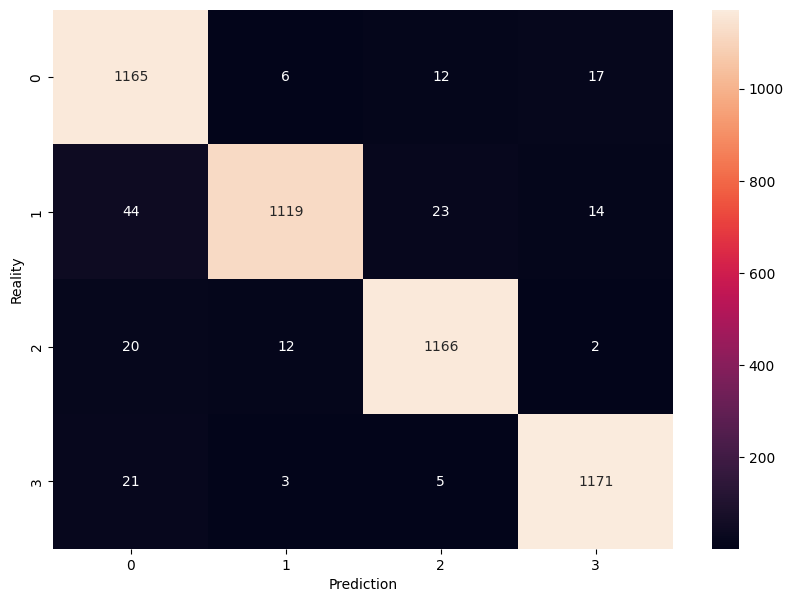

In [61]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize = (10,7))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Prediction')
plt.ylabel('Reality')